# Kiel MCG Preprocessing

**Question:** Can a transparent Python implementation of the documented preprocessing agree with the supplied processed version of one real recording?

We use **subject 1, trial 01**, chosen in advance as the first listed pair, with all eight channels. Channel 0 (sensor 0, −Y) is the presentation example. We reproduce sensitivity scaling and the nominal **100 Hz low-pass, 1 Hz high-pass and 50 Hz band-stop** stages. The release does not fully specify their implementation, so this is an **approximate reproduction**, with explicit assumptions.

The database contains healthy volunteers. Correlation and RMSE here measure agreement between two processing outputs; they do not measure clinical accuracy or demonstrate disease detection, heart-attack prediction, or wearable validation.

## Run this notebook

**Local:** Python 3.10–3.12 is recommended; the saved run used Python 3.12. Install `requirements.txt`, start JupyterLab in this folder, open this notebook, and choose **Restart Kernel and Run All Cells**.

**Google Colab:** Upload this `.ipynb` to [Colab](https://colab.research.google.com/), use a fresh CPU runtime, and choose **Run all**. The next cell installs the analysis dependencies before they are imported. No Google Drive mount, GPU, login to PhysioNet, or other project files are needed. Missing files are downloaded from a fixed allowlist. Figures and tables appear in the runtime's working directory; download them from the Files pane before the runtime ends.

The included data files allow local analysis without a network connection. If a missing download or checksum verification fails, the notebook stops with an error; it does not substitute data. Colab is a supported execution path, but the saved outputs were executed locally, not on a remote Colab runtime.

In [1]:
import os
import sys
import subprocess
# Detect Colab without importing its helpers before dependency installation.
IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
ANALYSIS_PACKAGES = [
    "numpy==2.2.6", "scipy==1.15.3", "matplotlib==3.10.3",
    "wfdb==4.3.0", "pandas==2.2.3",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *ANALYSIS_PACKAGES])
print("Environment:", "Google Colab" if IN_COLAB else "local Jupyter")

Environment: local Jupyter


In [2]:
from pathlib import Path
from urllib.request import Request, urlopen
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
import hashlib
import json
import csv
import platform
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
import wfdb
from IPython.display import display, Markdown

ROOT = Path.cwd()
DATA = ROOT / "data"
META = ROOT / "metadata"
FIGURES = ROOT / "figures"
for folder in (DATA, META, FIGURES):
    folder.mkdir(exist_ok=True)
BASE_URL = "https://physionet.org/files/kiel-cardio/1.0.0/"
RAW_NAME = "subject1_raw_trial01"
SUPPLIED_NAME = "subject1_preprocessed_trial01"
CHANNEL = 0
# These choices are fixed before looking at agreement metrics.
ASSUMED_RAW_FS = 51200.0       # inference from the 256:1 sample-count ratio, not the raw header
SENSITIVITY_V_PER_NT = 2.7     # manufacturer default; the recording's actual setting is unknown
PT_PER_V = 1000 / SENSITIVITY_V_PER_NT
EDGE_SECONDS = 5.0
WINDOW = (10.0, 15.0)
MAX_LAG_SECONDS = 0.5
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 170, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": 0.18})
COLORS = {"raw": "#7b8794", "reproduced": "#007f86", "supplied": "#df6c26"}
versions = {p: version(p) for p in ("numpy", "scipy", "matplotlib", "wfdb", "pandas")}
print("Python", platform.python_version())
print(json.dumps(versions, indent=2))

Python 3.12.14
{
  "numpy": "2.2.6",
  "scipy": "1.15.3",
  "matplotlib": "3.10.3",
  "wfdb": "4.3.0",
  "pandas": "2.2.3"
}


## 1 · Read the source and preserve provenance

The [versioned documentation](https://physionet.org/content/kiel-cardio/1.0.0/) and [release README](https://physionet.org/files/kiel-cardio/1.0.0/README.md) document the nominal preprocessing stages. We preserve the README, license, record list, subject metadata, and upstream checksums alongside the **one selected pair**. Headers are preserved unchanged.

The release is licensed under **Creative Commons Attribution–ShareAlike 4.0 International**. Original data are attributed to Erik Engelhardt, Norbert Frey and Gerhard Schmidt (2023), DOI [10.13026/q6r2-zz68](https://doi.org/10.13026/q6r2-zz68). See `metadata/LICENSE.txt`; modified analysis and derived figures retain attribution and the same license.

**Code search (2026-10-30):** No original v1.0.0 preprocessing implementation was located in the release listing, the linked [continuous database page](https://biomagnetic-sensing.de/index.php/data-bases/datasets/kiel-cardio-database), [KiRAT](https://kirat.de/) / its downloads, or the linked CRC repositories. The official [2022 MCG Quality Classes repository](https://github.com/CRC1261/BMT-2022-MCG-Quality-Classes) contains synthetic-signal filtering, not a verified pipeline for this release, so its settings are not copied as the original implementation. Some KiRAT subpages timed out; this is a scoped search, not proof that no code exists elsewhere.

In [3]:
FILES = {'metadata/RECORDS': {'sha256': '037e53603ba6c64f6c19c22cebba0a720cebaaa7cfc2598832194423311df6db',
                      'bytes': 10675,
                      'remote': 'RECORDS'},
 'metadata/README.md': {'sha256': 'ab67516b17ba2a15cc906ac803a8c90dd07ff105d8f621ff06f971f728bb1bee',
                        'bytes': 11127,
                        'remote': 'README.md'},
 'metadata/subject-info.csv': {'sha256': '9c50bff5be3870d442d4fa9b61501c5f2985a8c96d1860c7a822cda5e0ed581e',
                               'bytes': 98,
                               'remote': 'subject-info.csv'},
 'metadata/LICENSE.txt': {'sha256': 'e96e89b8862cbc9cd83a1689947ab359614fba6f82f680fc06fefda583c1f485',
                          'bytes': 16344,
                          'remote': 'LICENSE.txt'},
 'metadata/SHA256SUMS.txt': {'sha256': '6ca97a619cbd8cb6474b0acc79a5ba2e0422e5c69ad4e2d56b67ba60cf2c09c4',
                             'bytes': 70736,
                             'remote': 'SHA256SUMS.txt'},
 'data/subject1_raw_trial01.hea': {'sha256': '7e742d9e7f2d7994e2c431a9bc25daa593c9aeb97fc9b08d824ee7b5d44c7b46',
                                   'bytes': 941,
                                   'remote': 'data/subject1_raw_trial01.hea'},
 'data/subject1_raw_trial01.dat': {'sha256': '91c150e7131ff918b02f848e8582f79f5957264f2f92298a4df6947d168aabb5',
                                   'bytes': 42897408,
                                   'remote': 'data/subject1_raw_trial01.dat'},
 'data/subject1_preprocessed_trial01.hea': {'sha256': '4d538ac1f939d0840cd3a1080a220ed4a2ab4cbafd02c470637f97f54c13eda4',
                                            'bytes': 1023,
                                            'remote': 'data/subject1_preprocessed_trial01.hea'},
 'data/subject1_preprocessed_trial01.dat': {'sha256': 'f303743218ba89be786a4d5dd1a7f89fbe7686454cd26d61cf5d44853dc3233f',
                                            'bytes': 167568,
                                            'remote': 'data/subject1_preprocessed_trial01.dat'}}

# Only the nine named files above may be fetched. No recursive dataset download.
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def download_file(relative, info):
    target = ROOT / relative
    if target.exists() and file_sha256(target) == info["sha256"]:
        return "verified cache"
    url = BASE_URL + info["remote"]
    partial = target.with_suffix(target.suffix + ".part")
    try:
        if info["bytes"] > 10_000_000:
            # Small ranged requests avoid a single slow connection for the 43 MB raw file.
            chunk = 262144
            def get_part(start):
                end = min(start + chunk, info["bytes"]) - 1
                request = Request(url, headers={"Range": f"bytes={start}-{end}"})
                with urlopen(request, timeout=60) as response:
                    block = response.read()
                if len(block) != end - start + 1:
                    raise RuntimeError("Server did not return the requested byte range")
                return block
            with ThreadPoolExecutor(max_workers=8) as pool, partial.open("wb") as output:
                for block in pool.map(get_part, range(0, info["bytes"], chunk)):
                    output.write(block)
        else:
            with urlopen(url, timeout=60) as response, partial.open("wb") as output:
                output.write(response.read())
        if partial.stat().st_size != info["bytes"] or file_sha256(partial) != info["sha256"]:
            raise RuntimeError("Downloaded file size or SHA-256 does not match the pinned original")
        partial.replace(target)
    except Exception as error:
        partial.unlink(missing_ok=True)
        raise RuntimeError(f"Real-data access/verification failed for {url}: {error}") from error
    return "downloaded and verified"

for relative, info in FILES.items():
    print(relative, "—", download_file(relative, info))
# Also cross-check the four WFDB files against the preserved upstream checksum list.
upstream = {line.split()[1].lstrip("*"): line.split()[0]
            for line in (META / "SHA256SUMS.txt").read_text().splitlines()}
for relative, info in FILES.items():
    if relative.startswith("data/"):
        assert upstream[relative] == info["sha256"]
(ROOT / "data_manifest.json").write_text(json.dumps(FILES, indent=2) + "\n")
print(f"Total original files: {sum(v['bytes'] for v in FILES.values()):,} bytes")

metadata/RECORDS — verified cache
metadata/README.md — verified cache
metadata/subject-info.csv — verified cache
metadata/LICENSE.txt — verified cache
metadata/SHA256SUMS.txt — verified cache
data/subject1_raw_trial01.hea — verified cache
data/subject1_raw_trial01.dat — verified cache
data/subject1_preprocessed_trial01.hea — verified cache
data/subject1_preprocessed_trial01.dat — verified cache
Total original files: 43,175,920 bytes


In [4]:
source_readme = (META / "README.md").read_text()
license_text = (META / "LICENSE.txt").read_text()
print("Source preprocessing statement:")
for line in source_readme.splitlines():
    if "preprocessing includes" in line.lower():
        print(line)
assert "Attribution-ShareAlike" in license_text or "Attribution-ShareAlike" in source_readme
records = set((META / "RECORDS").read_text().splitlines())
assert "data/" + RAW_NAME in records and "data/" + SUPPLIED_NAME in records
print("\nSubject metadata (original release):")
print((META / "subject-info.csv").read_text())
print("Both selected names occur in RECORDS; source license retained.")

Source preprocessing statement:
For each trial, the raw data and the preprocessed data are provided. The preprocessing includes scaling by the sensitivity of the OPMs, 100 Hz low pass filtering, 1 Hz high pass filtering, and 50 Hz band stop filtering.

Subject metadata (original release):
Patient ID,Sex,Year of Birth
1,m,1996
2,m,1971
3,m,1992
4,m,1995
5,m,1988
6,m,1996
7,m,2000
Both selected names occur in RECORDS; source license retained.


## 2 · Check headers, units, channel order and time axes

WFDB stores integer samples. It reconstructs the stated physical value as **(integer − baseline) / ADC gain**. These ADC gains describe file encoding, not the magnetometer sensitivity. We let `wfdb` apply them once, then convert raw volts to picotesla separately.

A crucial inconsistency: both headers declare **200 Hz**, but the raw file has **3,574,784** samples per channel and the supplied processed file has **13,964**—exactly **256:1**. Taken literally, the raw header describes almost five hours, inconsistent with a roughly one-minute trial. Also, a digital 100 Hz low-pass cannot be designed at a 200 Hz rate because 100 Hz is the Nyquist limit.

For this V1 we explicitly **assume raw 51,200 Hz = 256 × 200 Hz**, and resample by 256 after filtering. This makes both durations 69.82 s. Equal durations alone do not prove the assumption; we also inspect the raw spectrum and waveform alignment below. The release does not confirm the raw rate or decimation procedure. The original header is never edited.

The manufacturer documents a default analog sensitivity of **2.7 V/nT**, with other selectable gains ([QuSpin command list](https://quspin.com/products-zf-opm/qzfm-command-list/)). We assume that default, so raw volts × 1000 / 2.7 gives pT. The session gain is not recorded; absolute-amplitude RMSE remains conditional on this assumption. We do not fit an amplitude multiplier to the supplied signal.

In [5]:
raw_header = wfdb.rdheader(str(DATA / RAW_NAME))
supplied = wfdb.rdrecord(str(DATA / SUPPLIED_NAME), physical=True)
assert raw_header.n_sig == supplied.n_sig == 8
assert raw_header.sig_name == supplied.sig_name
assert raw_header.units == ["V"] * 8 and supplied.units == ["pT"] * 8
assert supplied.fs == 200 and raw_header.fs == 200
assert raw_header.sig_len == supplied.sig_len * 256
assert raw_header.comments == supplied.comments
assert raw_header.fmt == supplied.fmt == ["212"] * 8
assert np.isfinite(supplied.p_signal).all()
FS = float(supplied.fs)
DOWNSAMPLE = int(ASSUMED_RAW_FS / FS)
assert ASSUMED_RAW_FS / FS == DOWNSAMPLE
assert 100 < ASSUMED_RAW_FS / 2
print(f"Raw header: {raw_header.sig_len:,} samples, declared {raw_header.fs} Hz, "
      f"literal duration {raw_header.sig_len/raw_header.fs:.2f} s")
print(f"Supplied: {supplied.sig_len:,} samples, {FS:g} Hz, duration {supplied.sig_len/FS:.2f} s")
print(f"ASSUMED raw rate {ASSUMED_RAW_FS:g} Hz; duration {raw_header.sig_len/ASSUMED_RAW_FS:.2f} s")
print("Header timing:", {"raw_base_time": str(raw_header.base_time),
                         "supplied_base_time": str(supplied.base_time),
                         "raw_skew": raw_header.skew, "supplied_skew": supplied.skew})
print("No absolute start timestamps are supplied; sample zero is the provisional common origin.")
print("\nChannel | name | raw ADC gain / baseline | supplied ADC gain / baseline")
for ch in range(8):
    print(f"{ch} | {raw_header.sig_name[ch]} | {raw_header.adc_gain[ch]:.6g} / "
          f"{raw_header.baseline[ch]} | {supplied.adc_gain[ch]:.6g} / {supplied.baseline[ch]}")
print("\nHeader comments:", raw_header.comments)
# A direct digital-to-physical check on a small portion guards against double calibration.
digital = wfdb.rdrecord(str(DATA / RAW_NAME), sampfrom=0, sampto=1024,
                        physical=False, channels=[CHANNEL]).d_signal[:, 0]
raw_check = wfdb.rdrecord(str(DATA / RAW_NAME), sampfrom=0, sampto=1024,
                          channels=[CHANNEL]).p_signal[:, 0]
assert np.allclose(raw_check, (digital - raw_header.baseline[CHANNEL]) / raw_header.adc_gain[CHANNEL])
print("WFDB gain/baseline conversion checked against digital samples.")

Raw header: 3,574,784 samples, declared 200 Hz, literal duration 17873.92 s
Supplied: 13,964 samples, 200 Hz, duration 69.82 s
ASSUMED raw rate 51200 Hz; duration 69.82 s
Header timing: {'raw_base_time': 'None', 'supplied_base_time': 'None', 'raw_skew': [None, None, None, None, None, None, None, None], 'supplied_skew': [None, None, None, None, None, None, None, None]}
No absolute start timestamps are supplied; sample zero is the provisional common origin.

Channel | name | raw ADC gain / baseline | supplied ADC gain / baseline
0 | Sensor 0  -Y | 8666.4 / -265 | 54.3553 / 24
1 | Sensor 0  Z | 8701.33 / 502 | 57.2883 / 937
2 | Sensor 1  -Y | 7545.47 / -336 | 48.2712 / 87
3 | Sensor 1  Z | 6533.74 / 454 | 42.9673 / 895
4 | Sensor 2  -Y | 6817.24 / -416 | 44.0176 / -73
5 | Sensor 2  X | 5355.38 / 152 | 44.5587 / 353
6 | Sensor 3  -Y | 7317.73 / -316 | 48.3281 / 49
7 | Sensor 3  X | 5395.89 / 441 | 43.2639 / 571

Header comments: ['<age>: 26', '<sex>: m', '<year of recording>: 2022', '<posi

## 3 · Look at the real raw signal

The plot uses the assumed raw time axis and shows the original voltage and its conditional magnetic-field conversion. This is the same **10–15 s** window used later. No filtering, centering, or amplitude fitting is applied to this raw trace.

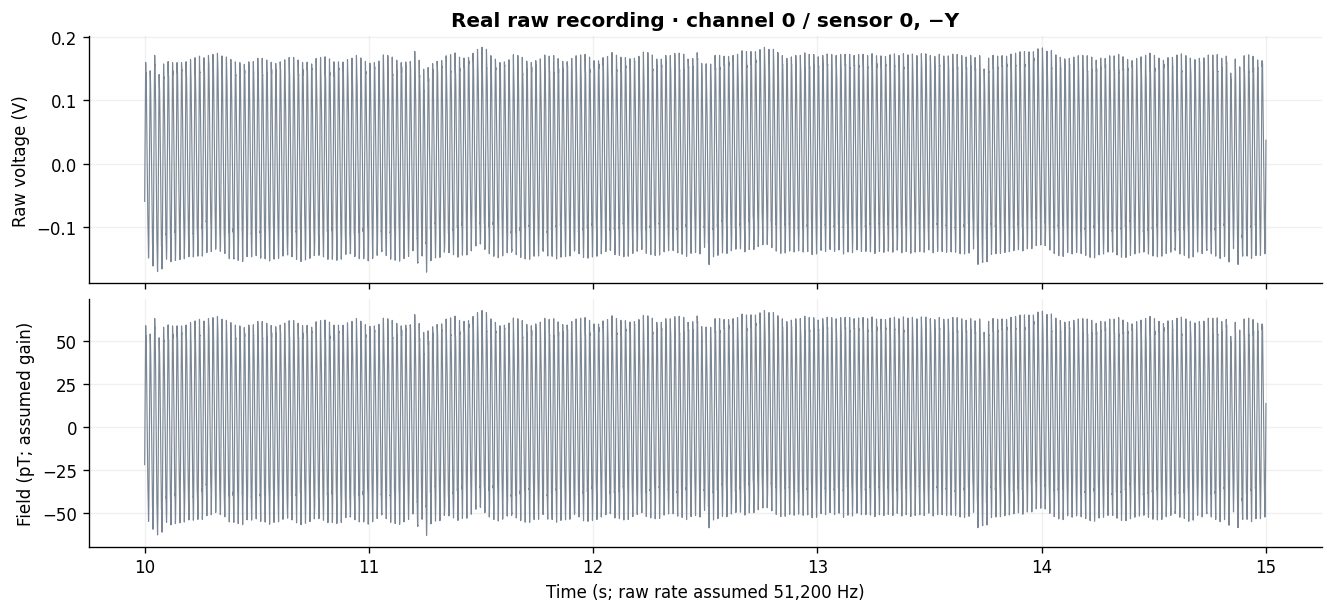

Largest raw PSD bin in 45–55 Hz under the assumed rate: 50.00 Hz
The same bin on the literal 200 Hz header axis: 0.195312 Hz
A peak near 50 Hz supports, but does not prove, the rate interpretation.


In [6]:
raw = wfdb.rdrecord(str(DATA / RAW_NAME), channels=[CHANNEL]).p_signal[:, 0]
assert len(raw) == raw_header.sig_len and np.isfinite(raw).all()
t_raw = np.arange(len(raw)) / ASSUMED_RAW_FS
raw_pt = raw * PT_PER_V
plot_raw = (t_raw >= WINDOW[0]) & (t_raw < WINDOW[1])
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
ax[0].plot(t_raw[plot_raw], raw[plot_raw], color=COLORS["raw"], lw=0.7)
ax[0].set(ylabel="Raw voltage (V)", title="Real raw recording · channel 0 / sensor 0, −Y")
ax[1].plot(t_raw[plot_raw], raw_pt[plot_raw], color=COLORS["raw"], lw=0.7)
ax[1].set(xlabel="Time (s; raw rate assumed 51,200 Hz)", ylabel="Field (pT; assumed gain)")
fig.savefig(FIGURES / "01_raw_segment.png")
plt.show()
# A spectral check of the time-axis hypothesis; it cannot independently establish the true rate.
f_raw_check, p_raw_check = signal.welch(raw, fs=ASSUMED_RAW_FS, nperseg=int(4 * ASSUMED_RAW_FS))
near_mains = (f_raw_check >= 45) & (f_raw_check <= 55)
mains_peak = float(f_raw_check[near_mains][np.argmax(p_raw_check[near_mains])])
print(f"Largest raw PSD bin in 45–55 Hz under the assumed rate: {mains_peak:.2f} Hz")
print(f"The same bin on the literal 200 Hz header axis: {mains_peak / DOWNSAMPLE:.6f} Hz")
print("A peak near 50 Hz supports, but does not prove, the rate interpretation.")

## 4 · Reproduce the documented stages with declared choices

A **high-pass** removes slow drift; a **low-pass** reduces fast fluctuations; a **band-stop** reduces a small range around the 50 Hz mains frequency.

The source specifies those nominal frequencies but leaves the following choices open. We fix them before calculating agreement:

| Choice | This notebook's assumption |
|---|---|
| Family and order | Butterworth: order 4 low-pass, order 4 high-pass; order 2 band-stop prototype (4th-order band-stop) |
| Band-stop edges | 49–51 Hz (width not specified by the release) |
| Phase and padding | Forward/backward `sosfiltfilt`, odd reflection, 5 seconds of padding; zero net phase |
| Stage construction | Concatenated second-order sections in source-listed order: low-pass → high-pass → band-stop |
| Rate conversion | `resample_poly`, down 256, Kaiser window β=5, constant boundary padding, after filtering |
| Scoring boundary | Exclude at least 5 seconds from each end of both signals; inspect 10-second trimming too |

All three filters run at the **assumed raw rate**, where 100 Hz is below Nyquist. The forward/backward operation squares the single-pass magnitude response: nominal Butterworth cutoffs become about −6 dB overall. Resampling adds its own antialias response close to the final 100 Hz Nyquist limit. These are consequential assumptions, not exact original settings.

Filtering is applied to each **full recording**, never separately to the short plotted window. The combined impulse-response plot below helps assess whether a 5-second exclusion is reasonable for this particular implementation; it cannot certify the original pipeline's edge behavior.

Processed channel 0: Sensor 0  -Y


Processed channel 1: Sensor 0  Z


Processed channel 2: Sensor 1  -Y


Processed channel 3: Sensor 1  Z


Processed channel 4: Sensor 2  -Y


Processed channel 5: Sensor 2  X


Processed channel 6: Sensor 3  -Y


Processed channel 7: Sensor 3  X
Raw samples at usable format-212 rails (−2047 or +2047), by channel: [3, 2, 5, 8, 1, 6, 2, 4]
Rail counts are descriptive: WFDB export may map its extrema to rails, so this does not prove sensor clipping.


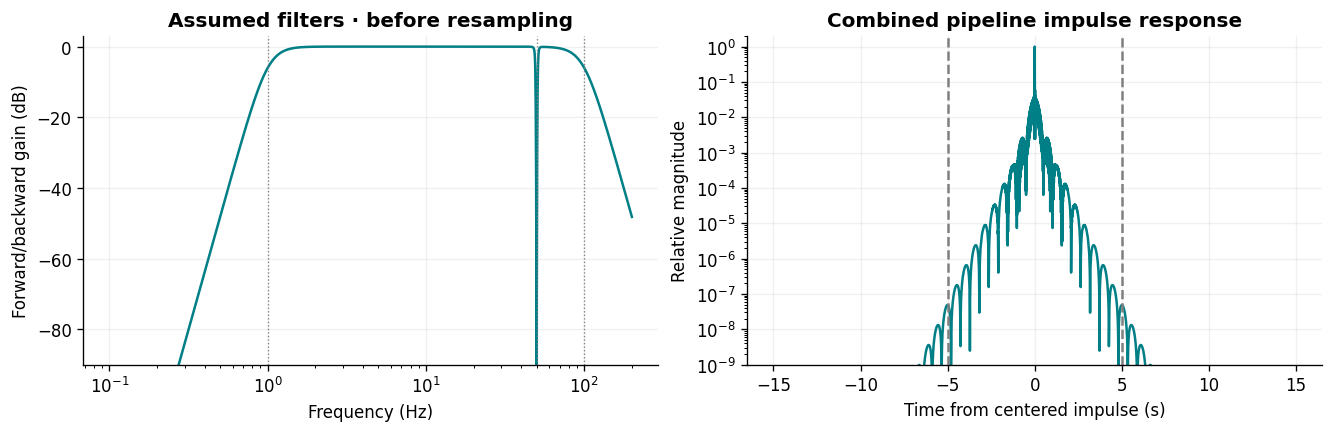

Peak relative impulse magnitude outside ±5 s: 4.84e-08


In [7]:
sos = np.vstack([
    signal.butter(4, 100, btype="lowpass", fs=ASSUMED_RAW_FS, output="sos"),
    signal.butter(4, 1, btype="highpass", fs=ASSUMED_RAW_FS, output="sos"),
    signal.butter(2, [49, 51], btype="bandstop", fs=ASSUMED_RAW_FS, output="sos"),
])
PADLEN = int(EDGE_SECONDS * ASSUMED_RAW_FS)
def reproduce(volts):
    field_pt = volts * PT_PER_V
    filtered = signal.sosfiltfilt(sos, field_pt, padtype="odd", padlen=PADLEN)
    return signal.resample_poly(filtered, 1, DOWNSAMPLE, window=("kaiser", 5.0), padtype="constant")

# Process channels in turn to keep memory use modest. Preserve only channel 0's full raw trace.
reproduced = np.empty_like(supplied.p_signal)
raw_rail_counts = []
for ch in range(8):
    record = wfdb.rdrecord(str(DATA / RAW_NAME), channels=[ch], physical=False)
    integers = record.d_signal[:, 0]
    assert not np.any(integers == -2048), f"Missing WFDB samples in channel {ch}"
    raw_rail_counts.append(int(np.count_nonzero((integers == -2047) | (integers == 2047))))
    volts = (integers.astype(float) - raw_header.baseline[ch]) / raw_header.adc_gain[ch]
    reproduced[:, ch] = reproduce(volts)
    print(f"Processed channel {ch}: {raw_header.sig_name[ch]}")
    del record, integers, volts
assert reproduced.shape == supplied.p_signal.shape and np.isfinite(reproduced).all()
print("Raw samples at usable format-212 rails (−2047 or +2047), by channel:", raw_rail_counts)
print("Rail counts are descriptive: WFDB export may map its extrema to rails, so this does not prove sensor clipping.")

frequency = np.geomspace(0.1, 200, 2500)
_, response = signal.sosfreqz(sos, worN=frequency, fs=ASSUMED_RAW_FS)
# A centered impulse includes the exact filtering + resampling operations used above.
impulse = np.zeros(int(30 * ASSUMED_RAW_FS))
impulse[len(impulse) // 2] = 1.0
impulse_out = reproduce(impulse)
impulse_time = np.arange(len(impulse_out)) / FS - 15
outside = np.abs(impulse_time) >= EDGE_SECONDS
impulse_tail_ratio = float(np.max(np.abs(impulse_out[outside])) / np.max(np.abs(impulse_out)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
ax[0].semilogx(frequency, 20 * np.log10(np.maximum(abs(response) ** 2, 1e-10)), color=COLORS["reproduced"])
ax[0].set(xlabel="Frequency (Hz)", ylabel="Forward/backward gain (dB)", ylim=(-90, 3),
          title="Assumed filters · before resampling")
for cutoff in (1, 50, 100): ax[0].axvline(cutoff, color="gray", ls=":", lw=0.8)
ax[1].semilogy(impulse_time, np.maximum(abs(impulse_out) / max(abs(impulse_out)), 1e-12), color=COLORS["reproduced"])
for boundary in (-EDGE_SECONDS, EDGE_SECONDS): ax[1].axvline(boundary, color="gray", ls="--")
ax[1].set(xlabel="Time from centered impulse (s)", ylabel="Relative magnitude", ylim=(1e-9, 2),
          title="Combined pipeline impulse response")
fig.savefig(FIGURES / "02_filter_and_edges.png")
plt.show()
print(f"Peak relative impulse magnitude outside ±5 s: {impulse_tail_ratio:.3g}")
del impulse, impulse_out

## 5 · Check alignment before scoring

Matching names and sample counts do not establish sample-level alignment. We search integer lags within **±0.5 s**, independently for each channel, using a temporary **5–30 Hz** view to emphasize the cardiac waveform rather than baseline or mains. This temporary filter is used only to estimate lag; it is never used for the reproduced output or RMSE.

A positive lag means the reproduced waveform occurs later: compare `reproduced[i + lag]` with `supplied[i]`. We report unshifted metrics as well as metrics after this reference-assisted shift, without fitting a gain, offset, polarity, or time warp. We check lags in early (10–30 s) and late (35–55 s) windows. Agreement between windows supports a fixed offset; disagreement would flag uncertain alignment. Integer lags cannot remove frequency-dependent phase differences or prove a correct absolute sampling rate.

Channel 0: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Channel 1: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Channel 2: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Channel 3: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Channel 4: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Channel 5: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Channel 6: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999


Channel 7: best lag +0 samples (+0.0 ms); early +0, late +0; shape correlation 0.99999
Alignment stable within one output sample across early/late windows: True


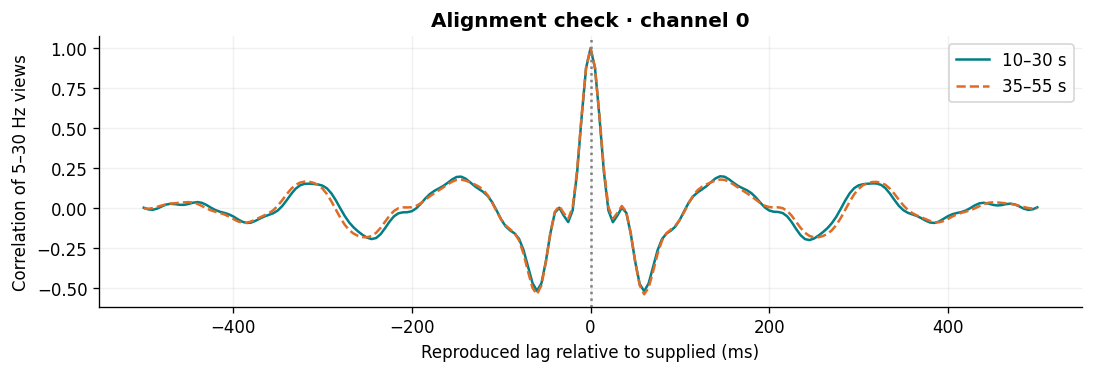

In [8]:
alignment_sos = signal.butter(3, [5, 30], btype="bandpass", fs=FS, output="sos")
shape_repro = signal.sosfiltfilt(alignment_sos, reproduced, axis=0)
shape_supplied = signal.sosfiltfilt(alignment_sos, supplied.p_signal, axis=0)
max_lag = int(MAX_LAG_SECONDS * FS)
lag_candidates = np.arange(-max_lag, max_lag + 1)

def lag_scores(ch, start, stop):
    indices = np.arange(int(start * FS), int(stop * FS))
    reference = shape_supplied[indices, ch]
    return np.array([np.corrcoef(shape_repro[indices + lag, ch], reference)[0, 1]
                     for lag in lag_candidates])

lags, early_lags, late_lags, peak_shape_corr = [], [], [], []
for ch in range(8):
    # The whole interior is used only for a transparent descriptive alignment estimate.
    scores = lag_scores(ch, EDGE_SECONDS + MAX_LAG_SECONDS,
                        len(reproduced) / FS - EDGE_SECONDS - MAX_LAG_SECONDS)
    best = int(lag_candidates[np.argmax(scores)])
    early = int(lag_candidates[np.argmax(lag_scores(ch, 10, 30))])
    late = int(lag_candidates[np.argmax(lag_scores(ch, 35, 55))])
    lags.append(best); early_lags.append(early); late_lags.append(late)
    peak_shape_corr.append(float(np.max(scores)))
    print(f"Channel {ch}: best lag {best:+d} samples ({best/FS*1000:+.1f} ms); "
          f"early {early:+d}, late {late:+d}; shape correlation {max(scores):.5f}")
lags = np.array(lags)
alignment_stable = bool(np.all(np.abs(np.array(early_lags) - np.array(late_lags)) <= 1)
                        and np.all(np.abs(lags) < max_lag))
print("Alignment stable within one output sample across early/late windows:", alignment_stable)
if not alignment_stable:
    print("CAUTION: alignment remains uncertain; interpret aligned scores conditionally.")
fig, ax = plt.subplots(figsize=(9, 3), layout="constrained")
ax.plot(lag_candidates / FS * 1000, lag_scores(CHANNEL, 10, 30), color=COLORS["reproduced"], label="10–30 s")
ax.plot(lag_candidates / FS * 1000, lag_scores(CHANNEL, 35, 55), color=COLORS["supplied"], ls="--", label="35–55 s")
ax.axvline(lags[CHANNEL] / FS * 1000, color="gray", ls=":")
ax.set(xlabel="Reproduced lag relative to supplied (ms)", ylabel="Correlation of 5–30 Hz views",
       title="Alignment check · channel 0")
ax.legend()
fig.savefig(FIGURES / "03_alignment.png")
plt.show()

## 6 · Compare the same channel and time window

The top panel retains the unfiltered raw values; the second shows both processed traces on a shared scale after the measured lag correction; the third shows their difference. The raw field units depend on the unconfirmed 2.7 V/nT sensitivity. No baseline subtraction or gain fitting is hidden in these panels. For a nonzero lag, the reproduced trace is plotted against `original time − lag` so all panels use the supplied signal's clock.

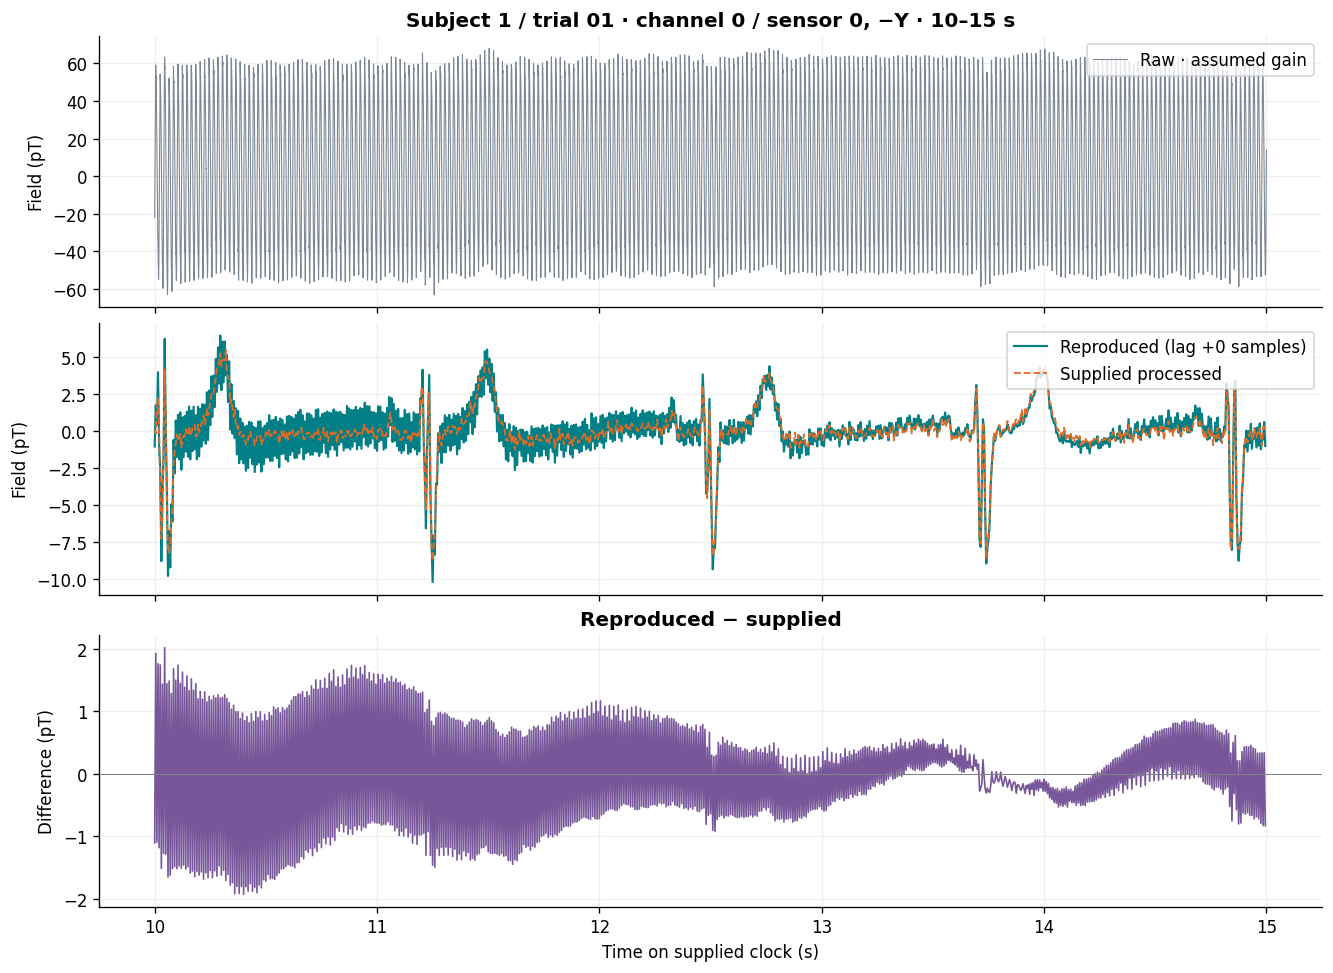

In [9]:
t = np.arange(supplied.sig_len) / FS
lag = int(lags[CHANNEL])
indices = np.flatnonzero((t >= WINDOW[0]) & (t < WINDOW[1]))
repro_window = reproduced[indices + lag, CHANNEL]
supplied_window = supplied.p_signal[indices, CHANNEL]
aligned_raw_time = t_raw - lag / FS
aligned_raw_mask = (aligned_raw_time >= WINDOW[0]) & (aligned_raw_time < WINDOW[1])
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True, layout="constrained")
ax[0].plot(aligned_raw_time[aligned_raw_mask], raw_pt[aligned_raw_mask], color=COLORS["raw"], lw=0.65, label="Raw · assumed gain")
ax[0].set(ylabel="Field (pT)", title="Subject 1 / trial 01 · channel 0 / sensor 0, −Y · 10–15 s")
ax[0].legend(loc="upper right")
ax[1].plot(t[indices], repro_window, color=COLORS["reproduced"], lw=1.3, label=f"Reproduced (lag {lag:+d} samples)")
ax[1].plot(t[indices], supplied_window, color=COLORS["supplied"], lw=1.1, ls="--", label="Supplied processed")
ax[1].set(ylabel="Field (pT)")
ax[1].legend(loc="upper right")
ax[2].plot(t[indices], repro_window - supplied_window, color="#77569a", lw=1)
ax[2].axhline(0, color="gray", lw=0.6)
ax[2].set(ylabel="Difference (pT)", xlabel="Time on supplied clock (s)", title="Reproduced − supplied")
fig.savefig(FIGURES / "04_signal_comparison.png")
plt.show()

## 7 · Compare frequency spectra, especially 50 Hz

Welch's method averages short Fourier-based power spectra. We use Hann windows of **4 seconds**, **50% overlap**, constant detrending, and **density** scaling. Raw and processed spectra therefore have matching **0.25 Hz bin spacing**, despite different assumed sample rates. The raw PSD is computed at its assumed full rate, not from an aliased plot subsample. All three use the common interior interval, excluding five seconds at each boundary.

The zoom and **49–51 Hz integrated power** describe residual mains-band energy. This band may include real signal energy as well as interference; suppression is not a clinical signal-quality score. A lag shift changes phase, not the power spectrum, so spectra use each signal's original sample origin.

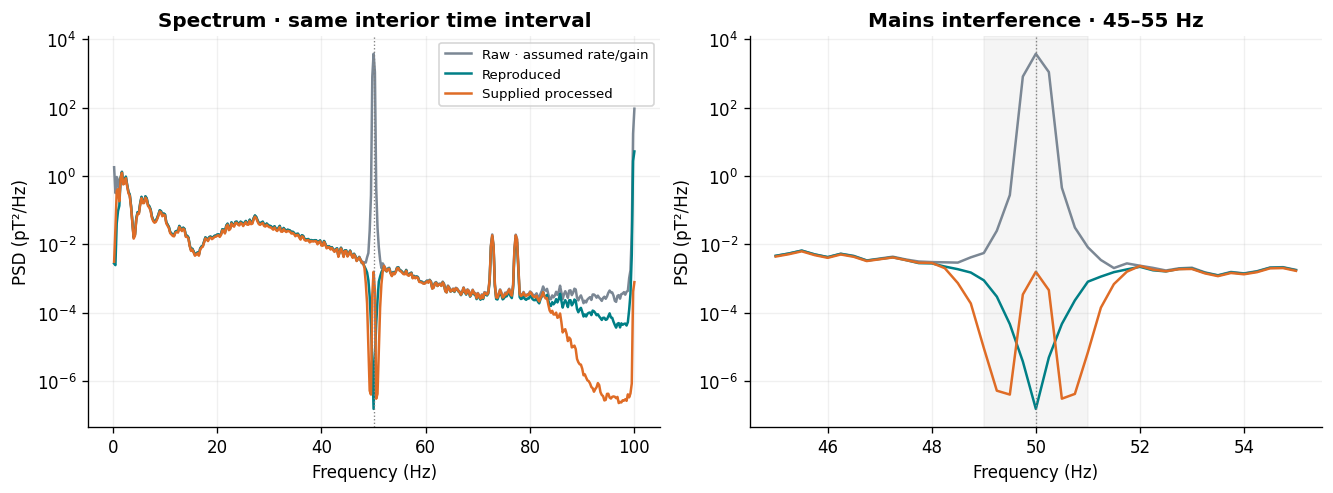

49–51 Hz power (pT²): raw 1426.76; reproduced 0.000365405; supplied 0.000590783
Relative to raw: reproduced -65.92 dB; supplied -63.83 dB


In [10]:
edge = int(EDGE_SECONDS * FS)
raw_edge = int(EDGE_SECONDS * ASSUMED_RAW_FS)
raw_eval = raw_pt[raw_edge:-raw_edge]
repro_eval = reproduced[edge:-edge, CHANNEL]
supplied_eval = supplied.p_signal[edge:-edge, CHANNEL]
def psd(values, fs):
    return signal.welch(values, fs=fs, window="hann", nperseg=int(4 * fs),
                        noverlap=int(2 * fs), detrend="constant", scaling="density")
f_raw, p_raw = psd(raw_eval, ASSUMED_RAW_FS)
f, p_repro = psd(repro_eval, FS)
f_sup, p_sup = psd(supplied_eval, FS)
assert np.allclose(f, f_sup) and np.allclose(f_raw[:len(f)], f)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for label, frequency, power, color in [
    ("Raw · assumed rate/gain", f_raw, p_raw, COLORS["raw"]),
    ("Reproduced", f, p_repro, COLORS["reproduced"]),
    ("Supplied processed", f, p_sup, COLORS["supplied"]),
]:
    keep = (frequency >= 0.25) & (frequency <= 100)
    ax[0].semilogy(frequency[keep], np.maximum(power[keep], 1e-12), label=label, color=color)
    zoom = (frequency >= 45) & (frequency <= 55)
    ax[1].semilogy(frequency[zoom], np.maximum(power[zoom], 1e-12), label=label, color=color)
ax[0].set(xlabel="Frequency (Hz)", ylabel="PSD (pT²/Hz)", title="Spectrum · same interior time interval")
ax[1].set(xlabel="Frequency (Hz)", ylabel="PSD (pT²/Hz)", title="Mains interference · 45–55 Hz")
ax[1].axvspan(49, 51, alpha=0.08, color="gray")
for axis in ax: axis.axvline(50, color="gray", ls=":", lw=0.8)
ax[0].legend(fontsize=8)
fig.savefig(FIGURES / "05_spectra.png")
plt.show()
def band_power(frequency, power, low=49, high=51):
    select = (frequency >= low) & (frequency <= high)
    return float(np.trapezoid(power[select], frequency[select]))
raw_50 = band_power(f_raw, p_raw)
repro_50 = band_power(f, p_repro)
supplied_50 = band_power(f, p_sup)
repro_50_db = float(10 * np.log10(repro_50 / raw_50))
supplied_50_db = float(10 * np.log10(supplied_50 / raw_50))
print(f"49–51 Hz power (pT²): raw {raw_50:.6g}; reproduced {repro_50:.6g}; supplied {supplied_50:.6g}")
print(f"Relative to raw: reproduced {repro_50_db:.2f} dB; supplied {supplied_50_db:.2f} dB")

## 8 · Measure agreement after checking alignment and boundaries

**Correlation** asks whether two traces rise and fall together (1 is perfect positive linear agreement). It is insensitive to a constant offset or positive scaling. **RMSE** is the typical size of the sample-by-sample difference in pT; it responds to scaling, offset, timing and waveform differences. Here we retain the physical values rather than normalizing them.

For every lag, both contributing sample indices must be at least five seconds from their own recording boundary. The table includes zero-lag scores, aligned scores, and an aligned RMSE with a stricter 10-second exclusion. The same data inform the lag estimate and the descriptive scores; these are not held-out validation results. No filter settings were selected to maximize correlation.

The supplied file is a **comparison reference**, not physiological ground truth. Differences can reflect the assumed filters, sensitivity, resampling, timing, finite precision, or missing implementation details. High agreement would still not establish clinical accuracy.

In [11]:
def paired_indices(lag, trim_seconds):
    trim = int(trim_seconds * FS)
    indices = np.arange(trim, supplied.sig_len - trim)
    return indices[(indices + lag >= trim) & (indices + lag < supplied.sig_len - trim)]

def agreement(ch, lag, trim_seconds):
    ix = paired_indices(lag, trim_seconds)
    x = reproduced[ix + lag, ch]
    y = supplied.p_signal[ix, ch]
    error = x - y
    return {
        "correlation": float(np.corrcoef(x, y)[0, 1]),
        "rmse_pt": float(np.sqrt(np.mean(error ** 2))),
        "mean_error_pt": float(np.mean(error)),
        "n_samples": len(ix), "start_s": float(ix[0] / FS), "end_exclusive_s": float((ix[-1] + 1) / FS),
    }

rows = []
for ch in range(8):
    zero = agreement(ch, 0, EDGE_SECONDS)
    aligned = agreement(ch, int(lags[ch]), EDGE_SECONDS)
    strict = agreement(ch, int(lags[ch]), 10)
    rows.append({"channel": ch, "name": supplied.sig_name[ch], "lag_samples": int(lags[ch]),
                 "alignment_shape_correlation": peak_shape_corr[ch],
                 "early_lag_samples": early_lags[ch], "late_lag_samples": late_lags[ch],
                 "zero_lag_correlation": zero["correlation"], "zero_lag_rmse_pt": zero["rmse_pt"],
                 "aligned_correlation": aligned["correlation"], "aligned_rmse_pt": aligned["rmse_pt"],
                 "aligned_mean_error_pt": aligned["mean_error_pt"], "trim10_rmse_pt": strict["rmse_pt"],
                 "scored_samples": aligned["n_samples"], "start_s": aligned["start_s"],
                 "end_exclusive_s": aligned["end_exclusive_s"]})
headers = ["Channel", "Lag (samples)", "r, zero lag", "RMSE, zero lag (pT)", "r, aligned", "RMSE, aligned (pT)", "RMSE, trim 10 s (pT)"]
lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
for row in rows:
    lines.append(f"| {row['channel']} | {row['lag_samples']:+d} | {row['zero_lag_correlation']:.5f} | "
                 f"{row['zero_lag_rmse_pt']:.4f} | {row['aligned_correlation']:.5f} | "
                 f"{row['aligned_rmse_pt']:.4f} | {row['trim10_rmse_pt']:.4f} |")
display(Markdown("\n".join(lines)))
with (ROOT / "metrics.csv").open("w", newline="") as output:
    writer = csv.DictWriter(output, fieldnames=list(rows[0]))
    writer.writeheader(); writer.writerows(rows)
results = {
    "dataset": "Kiel Cardio Database 1.0.0", "raw_record": RAW_NAME,
    "supplied_record": SUPPLIED_NAME, "python": platform.python_version(), "packages": versions,
    "assumed_raw_fs_hz": ASSUMED_RAW_FS, "raw_header_fs_hz": raw_header.fs,
    "supplied_fs_hz": FS, "raw_samples": raw_header.sig_len, "supplied_samples": supplied.sig_len,
    "assumed_sensitivity_v_per_nt": SENSITIVITY_V_PER_NT,
    "edge_trim_seconds": EDGE_SECONDS, "raw_mains_peak_assumed_hz": mains_peak,
    "impulse_tail_relative_peak_outside_5s": impulse_tail_ratio,
    "alignment_stable_early_late": alignment_stable,
    "mains_band_49_51_hz": {"raw_power_pt2": raw_50, "reproduced_power_pt2": repro_50,
                           "supplied_power_pt2": supplied_50, "reproduced_vs_raw_db": repro_50_db,
                           "supplied_vs_raw_db": supplied_50_db},
    "channels": rows,
}
(ROOT / "results.json").write_text(json.dumps(results, indent=2) + "\n")
example = rows[CHANNEL]
display(Markdown(
    f"**Channel 0 result:** aligned correlation **{example['aligned_correlation']:.5f}**, "
    f"RMSE **{example['aligned_rmse_pt']:.4f} pT**, lag **{example['lag_samples']:+d} samples**. "
    f"Scored supplied-clock interval: **{example['start_s']:.3f}–{example['end_exclusive_s']:.3f} s**, "
    f"with **{example['scored_samples']:,} samples**. "
    f"The stricter 10-second trim gives **{example['trim10_rmse_pt']:.4f} pT** RMSE."
))

| Channel | Lag (samples) | r, zero lag | RMSE, zero lag (pT) | r, aligned | RMSE, aligned (pT) | RMSE, trim 10 s (pT) |
|---|---|---|---|---|---|---|
| 0 | +0 | 0.76104 | 1.4760 | 0.76104 | 1.4760 | 1.3616 |
| 1 | +0 | 0.83611 | 1.6722 | 0.83611 | 1.6722 | 1.5362 |
| 2 | +0 | 0.70742 | 1.9914 | 0.70742 | 1.9914 | 1.8595 |
| 3 | +0 | 0.61692 | 2.3833 | 0.61692 | 2.3833 | 2.1771 |
| 4 | +0 | 0.54749 | 2.2282 | 0.54749 | 2.2282 | 2.1332 |
| 5 | +0 | 0.69983 | 2.8499 | 0.69983 | 2.8499 | 2.6482 |
| 6 | +0 | 0.74050 | 1.9346 | 0.74050 | 1.9346 | 1.8160 |
| 7 | +0 | 0.77248 | 2.6073 | 0.77248 | 2.6073 | 2.3855 |

**Channel 0 result:** aligned correlation **0.76104**, RMSE **1.4760 pT**, lag **+0 samples**. Scored supplied-clock interval: **5.000–64.820 s**, with **11,964 samples**. The stricter 10-second trim gives **1.3616 pT** RMSE.

## What the default run shows

The lower-frequency cardiac features line up in the time plot, and the early/late alignment checks select zero lag for all eight channels. The raw spectrum has a 50 Hz peak under the assumed raw clock, and both processing outputs strongly reduce power in the 49–51 Hz band.

The full-band match is incomplete: channel 0 has correlation **0.76104** and RMSE **1.47604 pT** over **5.00–64.82 s**. Across the eight channels, correlation ranges from **0.54749 to 0.83611**, and RMSE from **1.47604 to 2.84987 pT**. Correlation 0.761 is not “76.1% clinical accuracy.”

The spectrum exposes a practical reason not to call this an exact reproduction: our output retains substantially more energy close to **100 Hz**, while the supplied spectrum rolls off more strongly above roughly **80 Hz**; the shapes of the 50 Hz notches also differ. The assumed low-pass and rate-conversion responses can cause this. We report the mismatch rather than adjusting an undocumented filter until it scores well.

With a 10-second exclusion, channel 0 RMSE is **1.36157 pT**. This uses a different, shorter part of the signal, so its change does not by itself identify edge effects. The combined impulse tail beyond five seconds is small for our implementation. These checks support excluding filter boundaries while leaving the unknown original processing unresolved.

**Successfully reproduced:** real-data loading, physical file scaling, channel pairing, an explicitly conditional sensitivity conversion, the documented filter stages, resampling, visual/spectral comparisons and descriptive agreement metrics. **Still approximate:** true raw sampling rate, actual session sensitivity, exact filter design, phase/padding and original rate conversion. The bold numerical interpretation describes the included default run; changing configuration requires updating this paragraph.

## 9 · What I can explain in a presentation

1. **I used a real pair.** I selected one raw and one supplied processed recording of the same volunteer and trial, then verified their checksums.
2. **I checked the measurement scale and clock first.** WFDB converts stored integers into volts or picotesla. A 256-fold sample-count discrepancy required an explicitly assumed raw sample rate, and the sensor's actual voltage sensitivity was not recorded.
3. **I reproduced the stated types of processing.** I converted volts into an assumed magnetic-field scale, removed slow drift and high-frequency content, suppressed the 50 Hz band, and converted to the supplied sample rate.
4. **I compared the traces fairly.** I checked channel order and timing, showed the same time window, inspected spectra, and excluded filter boundaries before reporting correlation and RMSE.
5. **I reproduced the documented idea, with approximate implementation details.** The results above show agreement for this pair under my assumptions. Exact original filter coefficients, phase handling, gain and rate conversion remain unresolved.

### Limits of this V1

- One subject and trial cannot establish performance across the database. No disease labels or clinical evaluation are used.
- The raw-rate interpretation is plausible, not confirmed by acquisition metadata. The true acquisition configuration is the most important missing detail to request from the authors.
- The manufacturer default gain is an assumption. It can strongly change RMSE without changing positive correlation.
- Original filter family, order, bandwidth, phase, padding and resampling are unspecified. The supplied export is quantized (12-bit packed WFDB format); exact floating-point equality is not an appropriate expectation.
- A short impulse tail and the 10-second trim check support the chosen boundary exclusion for our filter; they do not eliminate every possible original-recording transient.
- Alignment is reference-assisted and limited to integer samples (5 ms at 200 Hz). No clinical ground truth, device calibration experiment, or wearable validation is performed.

**Outputs:** five PNG figures in `figures/`, plus `metrics.csv`, `results.json` and `data_manifest.json`. All results are calculated from the downloaded originals. Access or verification errors stop execution.

### Attribution and references

- Engelhardt, E., Frey, N., & Schmidt, G. (2023). *Kiel Cardio Database* (version 1.0.0). PhysioNet. [doi:10.13026/q6r2-zz68](https://doi.org/10.13026/q6r2-zz68). [Versioned documentation](https://physionet.org/content/kiel-cardio/1.0.0/).
- Pollard, T., et al. (2026). *PhysioNet as a global platform for biomedical research*. Nature Health. [doi:10.1038/s44360-026-00096-z](https://doi.org/10.1038/s44360-026-00096-z). This is the platform citation requested on the source page when inspected.
- [QuSpin QZFM command list](https://quspin.com/products-zf-opm/qzfm-command-list/), manufacturer sensitivity settings; not proof of the session gain.
- Software method references: [WFDB record reading](https://wfdb.readthedocs.io/en/latest/io.html), [SciPy `butter`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.butter.html), [`sosfiltfilt`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.sosfiltfilt.html), [`resample_poly`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html), [`welch`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html).